**Regularization** modifies the model's objective: instead of minimizing only the prediction error, it minimizes prediction error plus a penalty for large coefficient

The penalty discourages the model from relying too heavily on any single feature. It forces the coefficients to be small unless the evidence from the data is overwhelming
i magine location really is an important predictor of house prices.
If reducing its coefficient causes prediction errors to increase substantially, the model may retain a relatively large coefficient despite the penalty.
However, if the large coefficient contributes little to prediction accuracy, the model has less reason to keep it large

| Method     | Penalty                                                 | Effect on coefficients                                                    |
| ---------- | ------------------------------------------------------- | ------------------------------------------------------------------------- |
| Ridge (L2) | Sum of squared coefficients: \\(\lambda\sum w_i^2\\)    | Shrinks coefficients toward zero, but typically none become exactly zero. large coeeficient get higher penalty |
| Lasso (L1) | Sum of absolute coefficients: \\(\lambda\sum \|w_i\|\\) | Can shrink coefficients to exactly zero(effectively removing features from the model.).  all cofficient get same penalty  |

- regular regression use all features
- ridge : keeep but shrink them 
- liason : keep only most important features(feature selection)
- elastic : mixture of two(liason + ridge)


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge,Lasso,RidgeCV,LassoCV
from sklearn.preprocessing import StandardScaler
from category_encoders import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score


In [2]:
from wrangle import clean_files

df=clean_files("../data/buenos-aires-real-estate-*.csv")

target_col ="price_aprox_usd"
feature_cols=[col for col in df.columns if col not in target_col]
X=df[feature_cols]
y=df[target_col]

print(f"feature shape: {X.shape}")
print(f"Target shape : {y.shape}")
print(f"Feature columns: {X.columns.tolist()}")
type(X)

feature shape: (6247, 4)
Target shape : (6247,)
Feature columns: ['surface_covered_in_m2', 'lat', 'lon', 'neighborhood']


pandas.DataFrame

In [3]:
X_train_3,X_test_3,y_train_3,y_test_3=train_test_split(X,y,test_size=0.2,random_state=42)

print(f"Training set: {X_train_3.shape[0]} samples")
print(f"Test set: {X_test_3.shape[0]} samples")

Training set: 4997 samples
Test set: 1250 samples


### Why Feature Scaling Is Important for Regularization

- Regularization penalizes large coefficients.
- The size of a coefficient depends on the units used to measure a feature.
- Two coefficients can have different numerical values but represent the same real-world effect.
- Without scaling, regularization may penalize coefficients unfairly because it treats large numerical values more heavily.
- **Feature scaling** puts features on similar scales, allowing regularization to treat their coefficients more fairly.

**Example:**

A house's area can be measured in square metres (m²) or square centimetres (cm²). The coefficient values will differ depending on the units, even when they represent the same relationship with price.

## Example: House price prediction

Suppose you want to predict house prices using the house's area. The area can be measured in square metres (m²) or square centimetres (cm²).

Let's say a house has an area of 100 m², which is equal to 1,000,000 cm².

| Measurement              | House area | Coefficient | Contribution to predicted price |
| ------------------------ | ---------- | ----------- | ------------------------------- |
| Square metres (m²)       | 100        | 1,000       | 100 × 1,000 = 100,000           |
| Square centimetres (cm²) | 1,000,000  | 0.1         | 1,000,000 × 0.1 = 100,000       |

Both models predict the same contribution to the house price: 100,000. The coefficients differ only because the units differ.

### What happens with regularization?

Suppose we use L2 regularization, which penalizes squared coefficients.

| Measurement              | Coefficient | L2 penalty (\\(w^2\\)) |
| ------------------------ | ----------- | ---------------------- |
| Square metres (m²)       | 1,000       | 1,000,000              |
| Square centimetres (cm²) | 0.1         | 0.01                   |

Although the two coefficients represent the same real-world relationship, the first coefficient receives a much larger penalty.

This is the problem: regularization may penalize the square-metre model more heavily simply because of the measurement units.


**Remember:** Scale your features before applying L1 or L2 regularization so that differences in measurement units do not unfairly influence the penalty.

**StandardScaler** uts features on similar scales, succh that each feature so that it has a mean of 0 and a standard deviation of 1.

### StandardScaler and Data Leakage

- **Fit StandardScaler only on training data.** It learns the training data's mean and standard deviation.
- **Transform both training and test data** using the statistics learned from the training data.
- Never fit the scaler on the combined training and test datasets because the test data would influence the training process. This is called **data leakage**.
- **Use a Pipeline** to combine preprocessing and model training. It helps ensure that the scaler is fitted on the training data and applied correctly to the test data.

**Remember:** Fit on training data, transform training and test data using the same scaler.

**Why?** The test set represents unseen data. Its information must not influence how the model learns during training.

## Ridge

In [4]:
model_ridge_3=make_pipeline(
    OneHotEncoder(use_cat_names=True), # encode categorical columns
    StandardScaler(), #scale the feature to mean of 0 and std 1
    Ridge(alpha=1.0) # train ridge regression model, alpha controls how strongly Ridge penalizes large coefficients.
)
model_ridge_3

/opt/anaconda3/envs/buenos-env/lib/python3.13/site-packages/sklearn/externals/_numpydoc/docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('standardscaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,use_cat_names,True
,verbose,0
,cols,None
,drop_invariant,False
,return_df,True
,handle_missing,'value'
,handle_unknown,'value'




#### What does `alpha` do?

`alpha` controls how strongly Ridge penalizes large coefficients.

| Alpha value | Effect                                                                |
| ----------- | --------------------------------------------------------------------- |
| `alpha=0`   | No regularization; equivalent to ordinary least squares in principle. |
| `alpha=0.1` | Weak regularization.                                                  |
| `alpha=1.0` | The default regularization strength.                                  |
| `alpha=100` | Stronger regularization.                                              |

As `alpha` increases, coefficients are generally pushed closer to zero.



## pipeline

A Pipeline combines multiple machine learning steps into one object so they run in the correct order automatically.

Without a pipeline, you do each step separately. With a pipeline, you combine them.

A pipeline helps prevent data leakage only when it is fitted on the training data. It learns the preprocessing rules from the training data and applies those same rules to the test data.

In [5]:
model_ridge_3.fit(X_train_3,y_train_3)

# predict on training data
y_pred_ridge_train=model_ridge_3.predict(X_train_3)
rmse_ridge_train=root_mean_squared_error(y_train_3,y_pred_ridge_train)

# predict on test data
y_pred_ridge_test=model_ridge_3.predict(X_test_3)
rmse_ridge_test=root_mean_squared_error(y_test_3,y_pred_ridge_test)


print(f"Ridge training RMSE ${rmse_ridge_train: ,.2f}")
print(f"Ridge test RMSE ${rmse_ridge_test: ,.2f}")
print(f"difference ${rmse_ridge_train-rmse_ridge_test:,.2f}")

Ridge training RMSE $ 33,789.98
Ridge test RMSE $ 34,700.01
difference $-910.04


## lasso
                                                                                                                          

In [6]:
model_lasso_3=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    Lasso(alpha=100,max_iter=10000)
    
)
model_lasso_3.fit(X_train_3,y_train_3)
#predict on training data
y_pred_lasso_train=model_lasso_3.predict(X_train_3)
rmse_train_lasso=root_mean_squared_error(y_train_3,y_pred_lasso_train)

y_pred_lasso_test=model_lasso_3.predict(X_test_3)
rmse_test_lasso=root_mean_squared_error(y_test_3,y_pred_lasso_test)

print(f"lasso train RMSE, ${rmse_train_lasso:,.2f}")

print(f"lasso test RMSE, ${rmse_test_lasso:,.2f}")

print(f"lasso RMSE difference, ${rmse_train_lasso-rmse_test_lasso:,.2f} ")


lasso train RMSE, $33,806.62
lasso test RMSE, $34,687.48
lasso RMSE difference, $-880.86 


### Hyperparameter Tuning: Finding the Right Alpha
**Hyperparameters** are settings you configure before training a machine learning model.

### The bias-variance tradeoff

The bias–variance trade-off is about finding the right balance between underfitting and overfitting to achieve a model that generalizes well to unseen data.

**Bias** is the error from using too simple a model. A model with very high bias systematically misses real patterns in the data — it is not flexible enough to fit the training set well, let alone generalize.

**Variance** is the error from using too complex a model. A high-variance model fits training data so closely that small changes in the training set would produce wildly different predictions — it has memorized noise instead of learning signal.


 **The $\alpha$ dial:**
>
> - **$\alpha \to 0$:** No regularization — model is ordinary linear regression. Risk of high variance (overfitting): the model can fit training data perfectly but may not generalize.
> - **$\alpha \to \infty$:** Maximum regularization — all coefficients driven to zero. Risk of high bias (underfitting): the model makes the same prediction for every apartment regardless of features.
> - **Optimal $\alpha$:** Somewhere between these extremes — model is complex enough to capture real patterns but constrained enough to avoid memorizing noise.
>
This tradeoff produces a characteristic U-shaped performance curve when test error is plotted against :

> -  Left of the U: low  → overfitting → large train-test gap
> - Bottom of the U: optimal  → best generalization
> - Right of the U: high  → underfitting → both train and test error rise


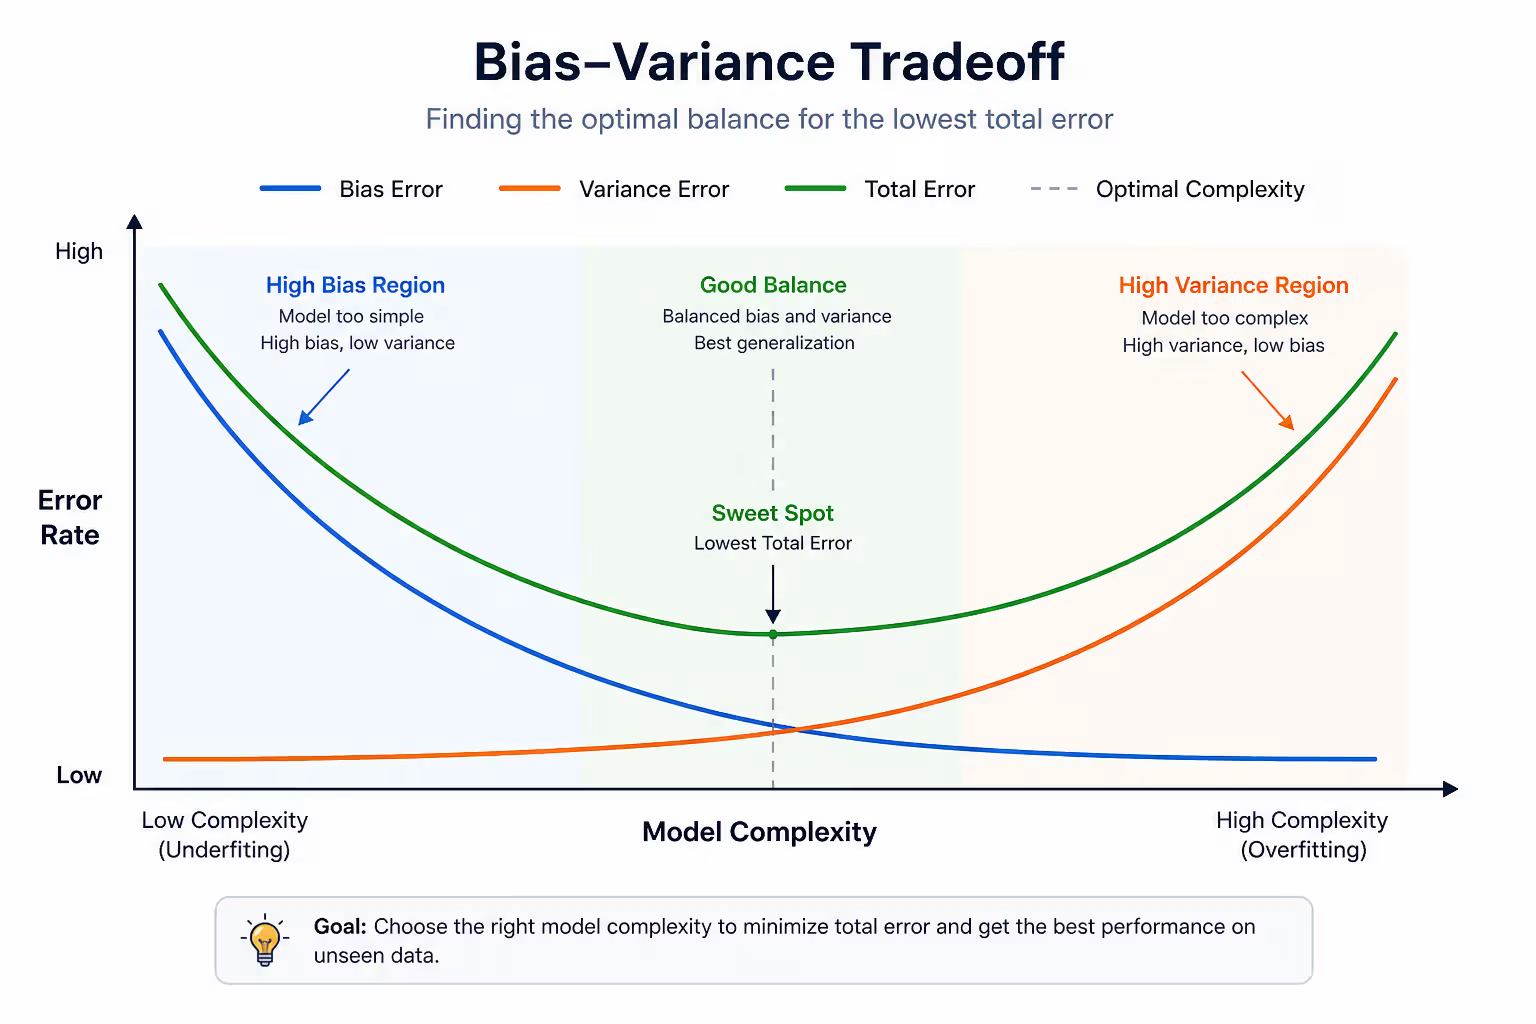

In [7]:
# test a wide range of allpha across 9 order of magnitude
alphas=[0.001,0.01,0.1,1,10,100,1000,10000,100000,1000000]
ridge_results=[]

for a in alphas:
    model=make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Ridge(alpha=a)
    )
    model.fit(X_train_3,y_train_3)
    
    # make prediction
    train_pred=model.predict(X_train_3)
    test_pred=model.predict(X_test_3)
    
    # calculate rmse
    train_rmse=root_mean_squared_error(y_train_3,train_pred)
    test_rmse=root_mean_squared_error(y_test_3,test_pred)
    
    ridge_results.append({
        "alpha" : a,
        "rmse_train": train_rmse,
        "rmse_test":test_rmse
        
    })
    
df_ridge_result=pd.DataFrame(ridge_results)
print(df_ridge_result)
    

         alpha    rmse_train     rmse_test
0        0.001  33789.975401  34700.069193
1        0.010  33789.975401  34700.068670
2        0.100  33789.975419  34700.063468
3        1.000  33789.977282  34700.013320
4       10.000  33790.159116  34699.694631
5      100.000  33805.346630  34711.500838
6     1000.000  34660.718202  35582.257211
7    10000.000  45803.747892  46864.391303
8   100000.000  56862.825843  57971.732259
9  1000000.000  58821.244995  59933.501264


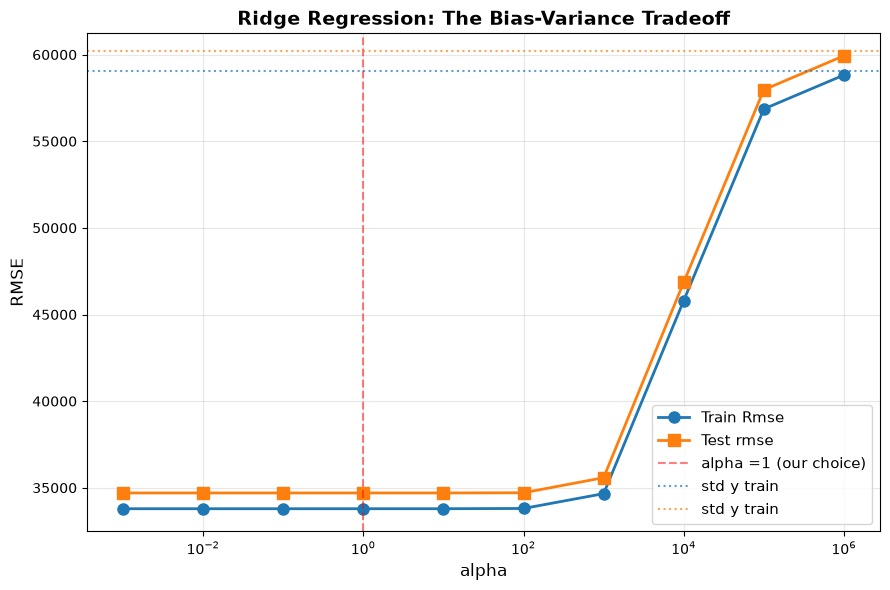

In [11]:
fig,ax=plt.subplots(figsize=(9,6))
ax.plot(df_ridge_result["alpha"],df_ridge_result["rmse_train"],marker='o',linewidth=2,markersize=8,label="Train Rmse")
ax.plot(df_ridge_result["alpha"],df_ridge_result["rmse_test"],marker="s",linewidth=2,markersize=8,label="Test rmse")
ax.axvline(x=1,color="red",linestyle='--',alpha=0.5,label="alpha =1 (our choice)")

## maximum regulazation
ax.axhline(y_train_3.std(),color="C0",linestyle=":",alpha=0.7,label="std y train")
ax.axhline(y_test_3.std(),color="C1",linestyle=":",alpha=0.7,label="std y train")
ax.set_xlabel("alpha",fontsize=12)
ax.set_ylabel("RMSE",fontsize=12)
ax.set_xscale("log")
ax.set_title("Ridge Regression: The Bias-Variance Tradeoff", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Ridge regression’s error changes as you turn up the regularization strength (alpha)
- X-axis (alpha, log scale): the regularization penalty. Higher alpha means the model’s coefficients are shrunk harder toward zero.
- Y-axis (RMSE): prediction error, in the units of your target variable (looks like prices or salaries, in the tens of thousands).
- Blue line (Train RMSE) and orange line (Test RMSE): error on the data the model learned from vs. data it hasn’t seen.
- Red dashed line: your chosen alpha = 1.
- Dotted horizontal lines (“std y train”): the standard deviation of the target, around 59,000 to 60,000. This is the error you’d get by always predicting the mean, so it acts as a “dumb baseline” ceiling. (Both are labeled “std y train”, but the blue one is likely the train std and the orange one the test std, so the second label is probably a typo.)
#### The three regions
- Alpha from 10⁻³ to about 10²: flat. Train RMSE is about 33,800 and test RMSE about 34,700. Regularization is so weak here that it barely changes anything, so the model behaves like ordinary linear regression. Your choice of alpha = 1 sits comfortably in this plateau, meaning it’s effectively not doing much.
- Alpha from 10² to 10⁴: the knee. Error starts climbing around alpha = 1000 and shoots up after that. The penalty is now strong enough to crush useful coefficients, so the model underfits (high bias).
Alpha of 10⁵ and above: collapse. Both train and test RMSE approach the baseline std (about 59,000 to 60,000). The coefficients are shrunk nearly to zero, so the model is basically predicting the mean for everyone.
#### Key takeaways
The bias-variance tradeoff in the title: increasing alpha adds bias (the model gets simpler and can’t fit the signal) in exchange for lower variance. Here you only see the bias cost, because the variance benefit never shows up.


As you increase alpha in Ridge regression, the coefficients shrink toward zero, but the error does not necessarily increase immediately.
Here's what happens:
1. Low alpha: The penalty is weak. The coefficients barely change, so the training and test RMSE remain almost flat.
2. Moderate alpha: The coefficients shrink more noticeably. The error might decrease or increase, depending on whether regularization improves generalization.
3. Very high alpha: The coefficients approach zero, and the model predicts approximately the mean training target. The model may underfit, causing training and test RMSE to increase.

As you increase alpha in Ridge regression, you generally trade variance for bias.
- Variance decreases: The model becomes less sensitive to the training data because the coefficients are shrunk.
- Bias increases: The model becomes more constrained and may struggle to capture some patterns in the data.

In [18]:
alphas=[0.1,1,10,100,1000]
lasso_result=[]

for a in alphas:
    model=make_pipeline(
        OneHotEncoder(use_cat_names=True),
        StandardScaler(),
        Lasso(alpha=a,max_iter=10000)
    )
    model.fit(X_train_3,y_train_3)
    
    # predict
    train_pred=model.predict(X_train_3)
    test_pred=model.predict(X_test_3)
    
    # rmse
    train_rmse=root_mean_squared_error(y_train_3,train_pred)
    test_rmse=root_mean_squared_error(y_test_3,test_pred)
    non_zero_features = (model.named_steps["lasso"].coef_ != 0).sum()

    lasso_result.append({
        "alpha":a,
        "train_rmse":train_rmse,
        "test_rmse":test_rmse,
        "non_zero_features": non_zero_features
    })

lasso_result_df=pd.DataFrame(lasso_result)
lasso_result_df

/opt/anaconda3/envs/buenos-env/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.235491e+11, tolerance: 1.743e+09
  model = cd_fast.enet_coordinate_descent(


,alpha,train_rmse,test_rmse,non_zero_features
0,0.1,33789.975420,34700.033044,59
1,1.0,33789.977894,34699.719098,58
2,10.0,33790.224500,34696.767399,58
3,100.0,33806.617640,34687.476265,55
4,1000.0,34383.728854,35135.609378,29


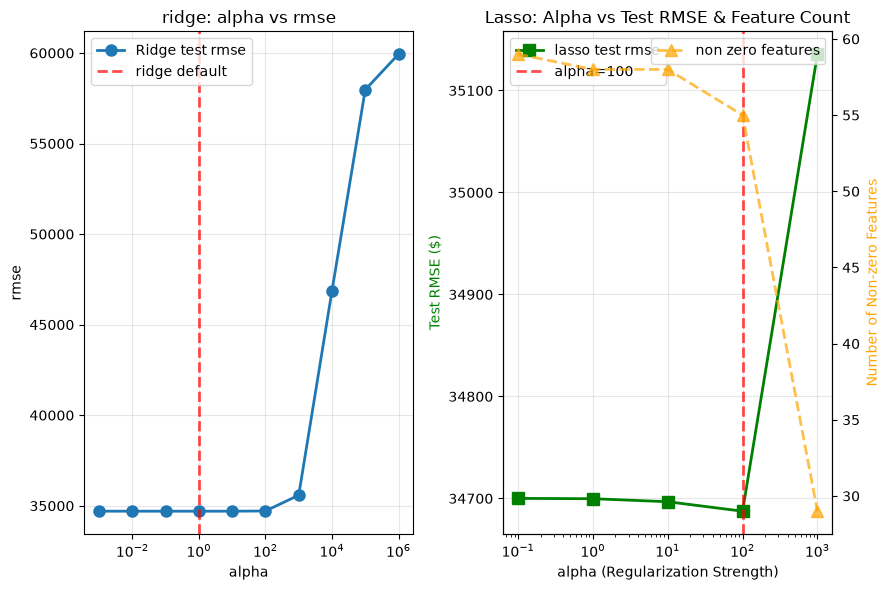

In [30]:
fig,axes=plt.subplots(1,2,figsize=(9,6))

axes[0].plot(df_ridge_result["alpha"],df_ridge_result["rmse_test"],marker="o",linewidth=2,markersize=8,label="Ridge test rmse")
axes[0].axvline(x=1,color="red",linestyle="--",alpha=0.7,linewidth=2,label="ridge default")
axes[0].set_xlabel("alpha")
axes[0].set_ylabel("rmse")
axes[0].set_xscale("log")
axes[0].set_title("ridge: alpha vs rmse")
axes[0].legend()
axes[0].grid(True,alpha=0.3)

## lasso
axes1_twin=axes[1].twinx()
axes[1].plot(lasso_result_df["alpha"],lasso_result_df["test_rmse"],marker="s",linewidth=2,markersize=8,color="green",label="lasso test rmse")
axes1_twin.plot(lasso_result_df["alpha"],lasso_result_df["non_zero_features"],marker='^',
                linewidth=2,markersize=8,color="orange",linestyle="--",alpha=0.7,label="non zero features")
axes[1].axvline(x=100,color="red",linestyle="--",alpha=0.7,linewidth=2,label="alpha=100")
axes[1].set_xlabel("alpha (Regularization Strength)")
axes[1].set_ylabel("Test RMSE ($)", color='green')
axes1_twin.set_ylabel("Number of Non-zero Features", color='orange')
axes[1].set_xscale("log")
axes[1].set_title("Lasso: Alpha vs Test RMSE & Feature Count")
axes[1].legend(loc='upper left')
axes1_twin.legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### cross validation
Cross-validation is a technique used to check how well a machine learning model is likely to perform on new, unseen data.

Instead of testing the model using just one train-test split, you split the training data into several parts and train and evaluate the model multiple times.

Example: 5-fold cross-validation

Imagine you have a dataset containing 100 houses and want to predict their prices.

You divide the data into 5 folds, each containing approximately 20 houses.

![cross_validation](../image/Screenshot%202026-10-13%20at%2008.17.37.png)

In [37]:
ridge_cv_model=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    RidgeCV(alphas=[0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000],cv=5)
)
ridge_cv_model.fit(X_train_3,y_train_3)



# extra optimal alpha
optimal_alpha_ridge=ridge_cv_model.named_steps["ridgecv"].alpha_
print(f"ridgeCv selected alpha:{optimal_alpha_ridge}")
print(f"ridge cv test rmse:${root_mean_squared_error(y_test_3,ridge_cv_model.predict(X_test_3))} ")

ridgeCv selected alpha:100.0
ridge cv test rmse:$34711.500838126216 


In [35]:
lasso_cv_model=make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LassoCV(alphas=[0.1, 1, 10, 100, 1000],cv=5,max_iter=10000)
)
lasso_cv_model.fit(X_train_3,y_train_3)

optimal_lasso_alpha=lasso_cv_model.named_steps["lassocv"].alpha_
print(f"\nLassoCV selected alpha: {optimal_lasso_alpha}")
print(f"Lasso CV Test RMSE: ${root_mean_squared_error(y_test_3, lasso_cv_model.predict(X_test_3)):,.2f}")
print(f"Non-zero features (Lasso CV): {(lasso_cv_model.named_steps['lassocv'].coef_ != 0).sum()}")



LassoCV selected alpha: 100.0
Lasso CV Test RMSE: $34,687.48
Non-zero features (Lasso CV): 55


**Why not always use CV?** 
- Cross-validation is computationally more expensive — it fits the model $k \times |\text{alphas}|$ times instead of once. For small datasets and fast models (like Ridge and Lasso), this cost is negligible. For large datasets or slow models, you might accept a slightly suboptimal
- k : number of crossvalidation

In [ ]:
coefficients=model_lasso_3